In [1]:
# STEP 1 — Install required libraries (Google Colab)
%pip -q install numpy pandas scipy scikit-learn matplotlib seaborn joblib gradio

In [2]:
# STEP 1 — Import libraries
import os
import glob
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import scipy.io as sio
from scipy import sparse

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# STEP 1 — Install required libraries (Google Colab)
%pip -q install numpy pandas scipy scikit-learn matplotlib seaborn joblib gradio

In [4]:
# STEP 1B — Import libraries
import os
import glob
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import scipy.io as sio
from scipy import sparse

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
# STEP 2 — Upload the dataset and load the MATLAB file
# Run this cell in Google Colab. Upload either the ZIP file or the .mat file directly.
from google.colab import files
from pathlib import Path

uploaded = files.upload()

if not uploaded:
    raise ValueError("No file was uploaded. Please upload your dataset ZIP or .mat file.")

# Find the uploaded ZIP or MATLAB file.
uploaded_names = list(uploaded.keys())
zip_files = [name for name in uploaded_names if name.lower().endswith(".zip")]
mat_files = [name for name in uploaded_names if name.lower().endswith(".mat")]

extract_path = "/content/traffic_data"
os.makedirs(extract_path, exist_ok=True)

# If a ZIP was uploaded, extract it and search all subfolders for .mat files.
if zip_files:
    with zipfile.ZipFile(zip_files[0], "r") as zf:
        zf.extractall(extract_path)
    mat_matches = glob.glob(os.path.join(extract_path, "**", "*.mat"), recursive=True)
# If a .mat file was uploaded directly, use it.
elif mat_files:
    mat_matches = [os.path.abspath(mat_files[0])]
else:
    raise ValueError("Please upload a .zip file containing a MATLAB .mat file, or upload the .mat file directly.")

if not mat_matches:
    raise FileNotFoundError(
        "No .mat file was found. Check that the ZIP actually contains a MATLAB .mat dataset."
    )

# Prefer traffic_dataset.mat if it exists; otherwise use the first .mat file found.
mat_path = next(
    (path for path in mat_matches if os.path.basename(path).lower() == "traffic_dataset.mat"),
    mat_matches[0]
)

# Load the MATLAB dataset.
mat_data = sio.loadmat(mat_path)

# Check that the expected input and target arrays are present.
required_keys = ["tra_X_tr", "tra_X_te", "tra_Y_tr", "tra_Y_te"]
missing_keys = [key for key in required_keys if key not in mat_data]

print("Dataset file:", mat_path)
print("MATLAB variables found:", [key for key in mat_data.keys() if not key.startswith("__")])

if missing_keys:
    raise KeyError(
        f"The selected MAT file is missing these expected variables: {missing_keys}. "
        "Please upload the correct traffic dataset MAT file."
    )

# Print shapes to help diagnose any dataset format mismatch.
for key in required_keys:
    arr = mat_data[key]
    print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")

print("Dataset loaded successfully.")


Saving traffic+flow+forecasting.zip to traffic+flow+forecasting.zip
Dataset file: /content/traffic_data/traffic_dataset.mat
MATLAB variables found: ['tra_X_tr', 'tra_X_te', 'tra_Y_tr', 'tra_Y_te', 'tra_adj_mat']
tra_X_tr: shape=(1, 1261), dtype=object
tra_X_te: shape=(1, 840), dtype=object
tra_Y_tr: shape=(36, 1261), dtype=float64
tra_Y_te: shape=(36, 840), dtype=float64
Dataset loaded successfully.


In [6]:
# STEP 3 — Convert MATLAB samples and create an 80/20 train-test split
# The original notebook used X_all and y_all without defining them.
# Here, split complete traffic samples first (not individual time steps),
# then expand each selected sample into its time-step rows.

from sklearn.model_selection import train_test_split


def extract_traffic_samples(x_mat, y_mat, split_name):
    """Return feature matrices and target vectors, one item per MATLAB sample."""
    x_flat = np.asarray(x_mat, dtype=object).reshape(-1)
    y_arr = np.asarray(y_mat)

    if y_arr.ndim != 2:
        raise ValueError(f"{split_name}: expected a 2D target matrix; got {y_arr.shape}.")

    n_samples = len(x_flat)
    if y_arr.shape[1] == n_samples:
        # Common MATLAB layout: (time steps, samples)
        y_samples = [np.asarray(y_arr[:, i], dtype=float).reshape(-1) for i in range(n_samples)]
    elif y_arr.shape[0] == n_samples:
        # Alternative layout: (samples, time steps)
        y_samples = [np.asarray(y_arr[i, :], dtype=float).reshape(-1) for i in range(n_samples)]
    else:
        raise ValueError(
            f"{split_name}: feature samples ({n_samples}) do not match target shape {y_arr.shape}."
        )

    x_samples = []
    for i, item in enumerate(x_flat):
        # MATLAB object cells can contain dense arrays or SciPy sparse matrices.
        if sparse.issparse(item):
            item = item.toarray()
        x = np.asarray(item, dtype=float)
        x = np.squeeze(x)
        if x.ndim == 1:
            x = x.reshape(-1, 1)
        if x.ndim != 2:
            raise ValueError(f"{split_name} sample {i}: expected a 2D feature matrix, got {x.shape}.")

        y = y_samples[i]
        # Orient features as (time steps, features).
        if x.shape[0] == len(y):
            pass
        elif x.shape[1] == len(y):
            x = x.T
        else:
            raise ValueError(
                f"{split_name} sample {i}: feature shape {x.shape} does not match "
                f"target length {len(y)}."
            )
        if x.shape[0] != len(y):
            raise ValueError(f"{split_name} sample {i}: feature and target time steps do not match.")
        x_samples.append(x)

    return x_samples, y_samples


# Extract the samples from the MATLAB-provided train and test partitions.
X_train_samples_original, y_train_samples_original = extract_traffic_samples(
    mat_data["tra_X_tr"], mat_data["tra_Y_tr"], "Original training data"
)
X_test_samples_original, y_test_samples_original = extract_traffic_samples(
    mat_data["tra_X_te"], mat_data["tra_Y_te"], "Original test data"
)

# Combine whole samples, then perform the requested 80/20 split at sample level.
# This avoids placing time steps from the same traffic sample in both sets.
X_all_samples = X_train_samples_original + X_test_samples_original
y_all_samples = y_train_samples_original + y_test_samples_original

if len(X_all_samples) != len(y_all_samples):
    raise ValueError("The number of feature samples and target samples does not match.")

all_sample_indices = np.arange(len(X_all_samples))
train_sample_indices, test_sample_indices = train_test_split(
    all_sample_indices,
    test_size=0.20,
    random_state=RANDOM_STATE,
    shuffle=True
)


def expand_samples(sample_indices):
    feature_rows = []
    target_rows = []
    for sample_index in sample_indices:
        x = X_all_samples[int(sample_index)]
        y = y_all_samples[int(sample_index)]
        if x.shape[0] != len(y):
            raise ValueError(f"Sample {sample_index}: X/y time-step counts differ.")
        feature_rows.append(x)
        target_rows.append(y)
    return np.vstack(feature_rows), np.concatenate(target_rows)


X_train_array, y_train_array = expand_samples(train_sample_indices)
X_test_array, y_test_array = expand_samples(test_sample_indices)

if X_train_array.shape[1] != X_test_array.shape[1]:
    raise ValueError("Training and testing feature counts do not match.")

feature_names = [f"feature_{i + 1}" for i in range(X_train_array.shape[1])]
X_train = pd.DataFrame(X_train_array, columns=feature_names)
X_test = pd.DataFrame(X_test_array, columns=feature_names)
y_train = pd.Series(y_train_array, name="traffic_flow")
y_test = pd.Series(y_test_array, name="traffic_flow")

print(f"Total traffic samples: {len(X_all_samples)}")
print(f"Training samples: {len(train_sample_indices)} ({len(train_sample_indices) / len(X_all_samples):.1%})")
print(f"Testing samples: {len(test_sample_indices)} ({len(test_sample_indices) / len(X_all_samples):.1%})")
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)
print("80/20 sample-level split completed successfully.")

Total traffic samples: 2101
Training samples: 1680 (80.0%)
Testing samples: 421 (20.0%)
X_train: (60480, 48) | y_train: (60480,)
X_test: (15156, 48) | y_test: (15156,)
80/20 sample-level split completed successfully.


In [7]:
# STEP 4 — Clean invalid values and impute missing values
# The imputer is fitted on training features only to avoid data leakage.

if list(X_train.columns) != list(X_test.columns):
    raise ValueError("Training and testing feature columns do not match.")

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

train_valid = np.isfinite(y_train.to_numpy(dtype=float))
test_valid = np.isfinite(y_test.to_numpy(dtype=float))

X_train = X_train.loc[train_valid].reset_index(drop=True)
y_train = y_train.loc[train_valid].reset_index(drop=True)
X_test = X_test.loc[test_valid].reset_index(drop=True)
y_test = y_test.loc[test_valid].reset_index(drop=True)

if len(X_train) < 3 or len(X_test) < 1:
    raise ValueError("Not enough valid rows remain after cleaning.")

imputer = SimpleImputer(strategy="median")
X_train_imputed_array = imputer.fit_transform(X_train)
X_test_imputed_array = imputer.transform(X_test)

feature_columns = list(X_train.columns)
X_train_imputed = pd.DataFrame(
    X_train_imputed_array, columns=feature_columns
)
X_test_imputed = pd.DataFrame(
    X_test_imputed_array, columns=feature_columns
)

print("Missing values after imputation (train):",
      int(X_train_imputed.isna().sum().sum()))
print("Preprocessing complete.")

Missing values after imputation (train): 0
Preprocessing complete.


In [8]:

# STEP 5 — Random Forest feature selection

from sklearn.ensemble import RandomForestRegressor
import pandas as pd

# Verify that training features and targets match
print("Training features:", X_train_imputed.shape)
print("Training targets:", y_train.shape)

if len(X_train_imputed) != len(y_train):
    raise ValueError(
        "Training features and targets do not match. "
        "Rerun the dataset conversion, split, and preprocessing cells."
    )

# Train Random Forest to calculate feature importance
feature_selector_rf = RandomForestRegressor(
    n_estimators=150,
    random_state=42,
    n_jobs=-1
)

feature_selector_rf.fit(X_train_imputed, y_train)

# Create a feature-importance table
importance_df = pd.DataFrame({
    "Feature": X_train_imputed.columns,
    "Importance": feature_selector_rf.feature_importances_
}).sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

# Select up to 25 important features
number_of_features = min(25, len(importance_df))
selected_features = importance_df.head(
    number_of_features
)["Feature"].tolist()

# Keep only the selected features
X_train_selected = X_train_imputed[selected_features].copy()
X_test_selected = X_test_imputed[selected_features].copy()

print("Selected features:", len(selected_features))
display(importance_df.head(number_of_features))


Training features: (60480, 48)
Training targets: (60480,)
Selected features: 25


,Feature,Importance
0,feature_10,0.932858
1,feature_18,0.007333
2,feature_1,0.005896
3,feature_2,0.005519
4,feature_9,0.005503
5,feature_8,0.005166
6,feature_6,0.004563
7,feature_3,0.004486
8,feature_4,0.003823
9,feature_7,0.003492


In [9]:
# STEP 6 — Train and compare four baseline regression models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=12, random_state=RANDOM_STATE
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, learning_rate=0.05,
        max_depth=3, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=150, max_depth=None,
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2 Score": r2_score(y_true, y_pred)
    }

trained_models = {}
baseline_predictions = {}
baseline_rows = []

for name, estimator in models.items():
    print("Training", name, "...")
    estimator.fit(X_train_selected, y_train)
    pred = estimator.predict(X_test_selected)
    metrics = regression_metrics(y_test, pred)

    trained_models[name] = estimator
    baseline_predictions[name] = pred
    baseline_rows.append({
        "Model": name,
        **metrics,
        "Selected Features": len(selected_features)
    })

baseline_results = pd.DataFrame(baseline_rows).sort_values(
    "RMSE", ascending=True
).reset_index(drop=True)

display(baseline_results)
baseline_results.to_csv("/content/traffic_model_baseline_comparison.csv", index=False)

Training Linear Regression ...
Training Decision Tree ...
Training Gradient Boosting ...
Training Random Forest ...


,Model,MAE,RMSE,R2 Score,Selected Features
0,Random Forest,0.025777,0.039643,0.960511,25
1,Gradient Boosting,0.030826,0.045447,0.948103,25
2,Decision Tree,0.029750,0.045886,0.947095,25
3,Linear Regression,0.031708,0.047131,0.944185,25


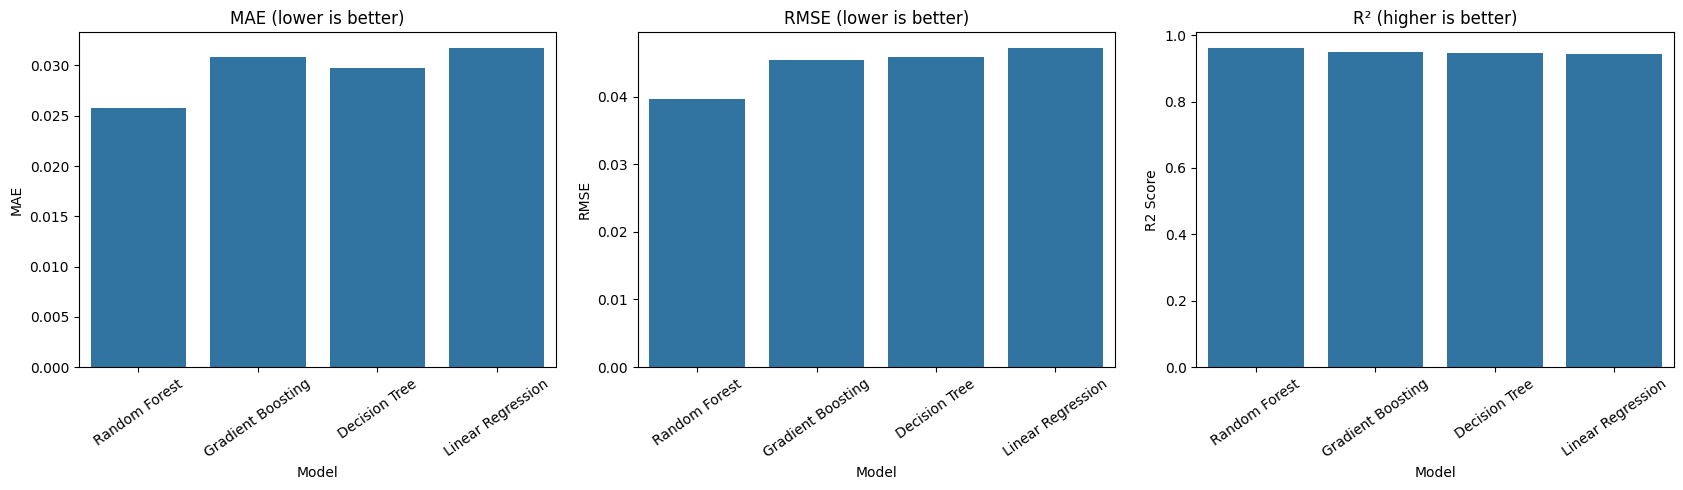

Baseline models ranked by RMSE:


,Model,MAE,RMSE,R2 Score
0,Random Forest,0.025777,0.039643,0.960511
1,Gradient Boosting,0.030826,0.045447,0.948103
2,Decision Tree,0.029750,0.045886,0.947095
3,Linear Regression,0.031708,0.047131,0.944185


In [10]:
# STEP 7 — Compare baseline model metrics
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(data=baseline_results, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("MAE (lower is better)")
axes[0].tick_params(axis="x", rotation=35)

sns.barplot(data=baseline_results, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("RMSE (lower is better)")
axes[1].tick_params(axis="x", rotation=35)

sns.barplot(data=baseline_results, x="Model", y="R2 Score", ax=axes[2])
axes[2].set_title("R² (higher is better)")
axes[2].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

print("Baseline models ranked by RMSE:")
display(baseline_results[["Model", "MAE", "RMSE", "R2 Score"]])

In [11]:
# STEP 8 — Hyperparameter tuning specifically for Random Forest
# GridSearchCV only sees training data. The test set remains held out for final evaluation.

rf_for_tuning = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": [1.0]
}

cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

grid_search = GridSearchCV(
    estimator=rf_for_tuning,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_search.fit(X_train_selected, y_train)

tuned_rf = grid_search.best_estimator_
print("Best Random Forest parameters:")
print(grid_search.best_params_)
print("Best cross-validation RMSE:", round(-grid_search.best_score_, 6))

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best Random Forest parameters:
{'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best cross-validation RMSE: 0.037586


In [12]:
# STEP 9 — Evaluate tuned Random Forest on the held-out test set
tuned_train_pred = tuned_rf.predict(X_train_selected)
tuned_test_pred = tuned_rf.predict(X_test_selected)

train_metrics = regression_metrics(y_train, tuned_train_pred)
test_metrics = regression_metrics(y_test, tuned_test_pred)

tuned_results = pd.DataFrame([
    {"Dataset": "Train", **train_metrics},
    {"Dataset": "Test", **test_metrics}
])

print("Tuned Random Forest metrics:")
display(tuned_results.round(6))

final_comparison = pd.concat([
    baseline_results[["Model", "MAE", "RMSE", "R2 Score"]],
    pd.DataFrame([{
        "Model": "Random Forest (Tuned)",
        **test_metrics
    }])
], ignore_index=True).sort_values("RMSE").reset_index(drop=True)

print("Baseline models compared with tuned Random Forest:")
display(final_comparison.round(6))
final_comparison.to_csv("/content/traffic_model_comparison_with_tuned_rf.csv", index=False)

prediction_df = pd.DataFrame({
    "Actual Traffic Flow": np.asarray(y_test, dtype=float),
    "Predicted Traffic Flow": np.asarray(tuned_test_pred, dtype=float),
    "Absolute Error": np.abs(np.asarray(y_test, dtype=float) - np.asarray(tuned_test_pred, dtype=float))
})
prediction_df.to_csv("/content/tuned_random_forest_predictions.csv", index=False)
display(prediction_df.head(10))

Tuned Random Forest metrics:


,Dataset,MAE,RMSE,R2 Score
0,Train,0.008836,0.013606,0.995474
1,Test,0.025762,0.039637,0.960524


Baseline models compared with tuned Random Forest:


,Model,MAE,RMSE,R2 Score
0,Random Forest (Tuned),0.025762,0.039637,0.960524
1,Random Forest,0.025777,0.039643,0.960511
2,Gradient Boosting,0.030826,0.045447,0.948103
3,Decision Tree,0.029750,0.045886,0.947095
4,Linear Regression,0.031708,0.047131,0.944185


,Actual Traffic Flow,Predicted Traffic Flow,Absolute Error
0,0.368519,0.379295,0.010775
1,0.634283,0.554937,0.079346
2,0.183092,0.229110,0.046018
3,0.243811,0.321826,0.078015
4,0.702943,0.605883,0.097060
5,0.548342,0.529897,0.018445
6,0.709482,0.683517,0.025965
7,0.478281,0.452279,0.026002
8,0.538533,0.514573,0.023961
9,0.573564,0.521467,0.052097


In [13]:
# STEP 10 — Save and reload the tuned Random Forest model package
model_package = {
    "model_name": "Random Forest (Tuned)",
    "model": tuned_rf,
    "imputer": imputer,
    "feature_selector_model": feature_selector_rf,
    "feature_columns": feature_columns,
    "selected_features": selected_features,
    "best_params": grid_search.best_params_,
    "baseline_results": baseline_results,
    "final_comparison": final_comparison,
    "test_metrics": test_metrics
}

model_path = "/content/traffic_flow_prediction_tuned_random_forest.joblib"
joblib.dump(model_package, model_path)
print("Saved model package:", model_path)

loaded_package = joblib.load(model_path)
loaded_model = loaded_package["model"]
reload_predictions = loaded_model.predict(X_test_selected)

print("Reload verification — maximum prediction difference:",
      float(np.max(np.abs(reload_predictions - tuned_test_pred))))

Saved model package: /content/traffic_flow_prediction_tuned_random_forest.joblib
Reload verification — maximum prediction difference: 3.3306690738754696e-16


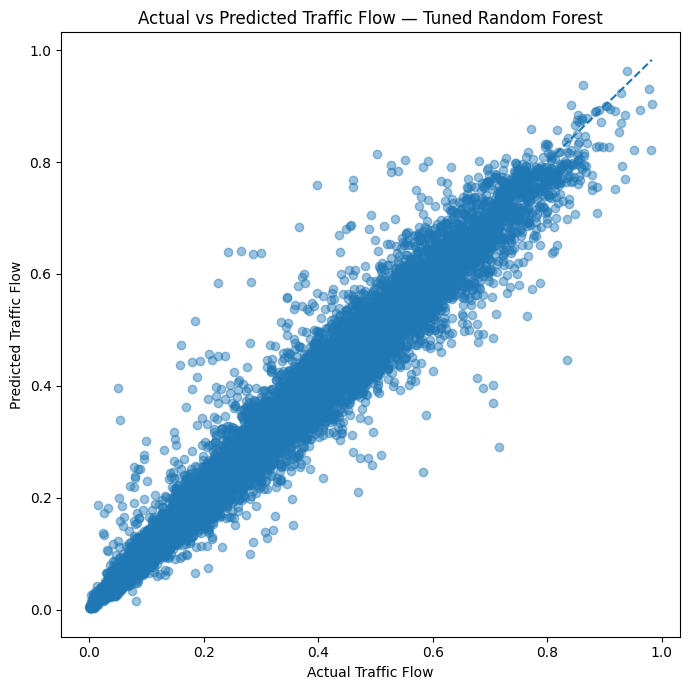

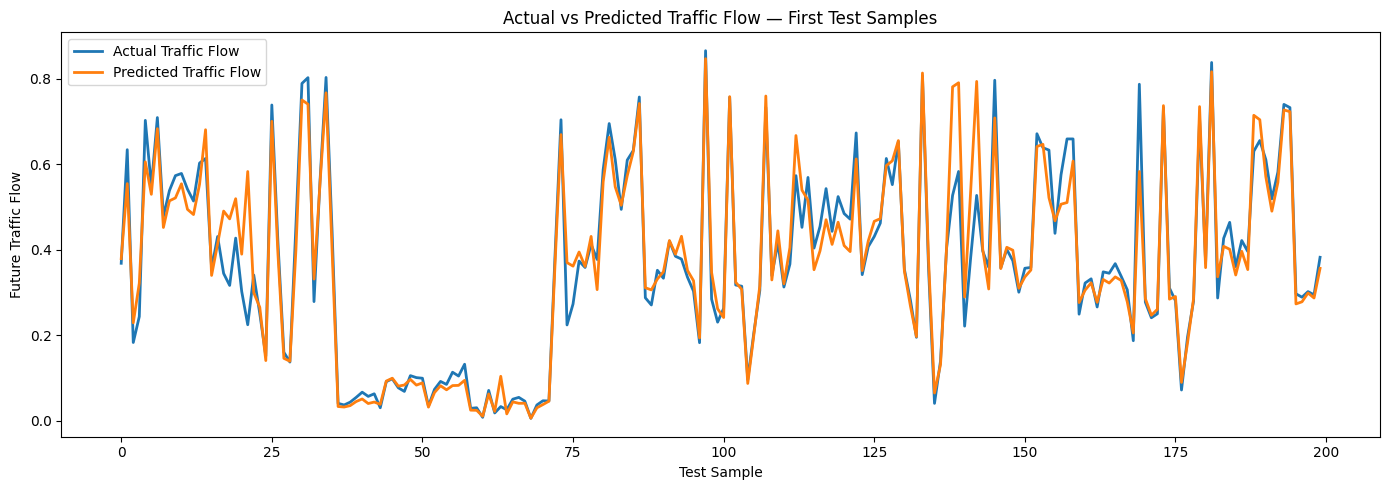

Actual vs predicted graphs saved.


In [14]:
# STEP 11 — Actual vs Predicted graphs (final model)
actual_values = np.asarray(y_test, dtype=float).reshape(-1)
predicted_values = np.asarray(tuned_test_pred, dtype=float).reshape(-1)

# Scatter plot: points close to the diagonal indicate better predictions.
plt.figure(figsize=(7, 7))
plt.scatter(actual_values, predicted_values, alpha=0.45)
low = min(actual_values.min(), predicted_values.min())
high = max(actual_values.max(), predicted_values.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual Traffic Flow")
plt.ylabel("Predicted Traffic Flow")
plt.title("Actual vs Predicted Traffic Flow — Tuned Random Forest")
plt.tight_layout()
plt.savefig("/content/actual_vs_predicted_scatter.png", dpi=300)
plt.show()

# Line plot for the first 200 test samples.
n_plot = min(200, len(actual_values))
plt.figure(figsize=(14, 5))
plt.plot(actual_values[:n_plot], label="Actual Traffic Flow", linewidth=2)
plt.plot(predicted_values[:n_plot], label="Predicted Traffic Flow", linewidth=2)
plt.xlabel("Test Sample")
plt.ylabel("Future Traffic Flow")
plt.title("Actual vs Predicted Traffic Flow — First Test Samples")
plt.legend()
plt.tight_layout()
plt.savefig("/content/actual_vs_predicted_line.png", dpi=300)
plt.show()

print("Actual vs predicted graphs saved.")

In [15]:
# STEP 12 — Gradio frontend for Traffic Flow Prediction
# This dashboard uses the 25 selected features. The defaults are the training-set
# medians of those features, so the app opens with valid example inputs.

import gradio as gr

selected_defaults = X_train_imputed[selected_features].median(numeric_only=True)
actual_values = np.asarray(y_test, dtype=float).reshape(-1)
predicted_values = np.asarray(tuned_test_pred, dtype=float).reshape(-1)

def predict_traffic(*values):
    try:
        if len(values) != len(selected_features):
            raise ValueError("Unexpected number of feature values.")

        cleaned_values = []
        for name, value in zip(selected_features, values):
            if value is None or not np.isfinite(float(value)):
                raise ValueError(f"Enter a valid numeric value for {name}.")
            cleaned_values.append(float(value))

        input_df = pd.DataFrame([cleaned_values], columns=selected_features)
        prediction = float(loaded_model.predict(input_df)[0])

        return (
            f"{prediction:,.4f}",
            f"**Prediction successful.** Tuned Random Forest predicted future traffic flow: **{prediction:,.4f}**."
        )
    except Exception as exc:
        return "Prediction failed", f"Please check the inputs. Details: {exc}"

def compare_record(index):
    i = int(index)
    if not 0 <= i < len(actual_values):
        return pd.DataFrame(), None

    actual = float(actual_values[i])
    predicted = float(predicted_values[i])
    table = pd.DataFrame({
        "Metric": ["Actual Traffic Flow", "Predicted Traffic Flow", "Absolute Error"],
        "Value": [actual, predicted, abs(actual - predicted)]
    })

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(["Actual", "Predicted"], [actual, predicted])
    ax.set_title(f"Actual vs Predicted — Test Record {i}")
    ax.set_ylabel("Traffic Flow")
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    return table, fig

def show_comparison_graph(number_of_records):
    count = max(1, min(int(number_of_records), len(actual_values)))
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(actual_values[:count], label="Actual", linewidth=2)
    ax.plot(predicted_values[:count], label="Predicted", linewidth=2)
    ax.set_title("Actual vs Predicted Traffic Flow")
    ax.set_xlabel("Test Record")
    ax.set_ylabel("Traffic Flow")
    ax.legend()
    ax.grid(True, alpha=0.25)
    fig.tight_layout()
    return fig

with gr.Blocks(theme=gr.themes.Soft(), title="Traffic Flow Prediction Dashboard") as demo:
    gr.Markdown("# Traffic Flow Prediction Dashboard")
    gr.Markdown(
        "Predict future traffic flow with a Random Forest model tuned using GridSearchCV. "
        "The input fields are the 25 features selected from the training data."
    )

    with gr.Row():
        with gr.Column():
            gr.Markdown("### Test MAE")
            gr.Markdown(f"## {test_metrics['MAE']:.4f}")
        with gr.Column():
            gr.Markdown("### Test RMSE")
            gr.Markdown(f"## {test_metrics['RMSE']:.4f}")
        with gr.Column():
            gr.Markdown("### Test R²")
            gr.Markdown(f"## {test_metrics['R2 Score']:.4f}")

    gr.Markdown("**Selected model:** Tuned Random Forest")
    gr.Markdown("**Best hyperparameters:**")
    gr.JSON(value=grid_search.best_params_)

    with gr.Tab("Traffic Flow Prediction"):
        gr.Markdown("Enter values for the selected traffic features. Defaults are training medians.")
        input_fields = []
        for start in range(0, len(selected_features), 5):
            end = min(start + 5, len(selected_features))
            with gr.Accordion(f"Selected Features {start + 1}–{end}", open=(start == 0)):
                with gr.Row():
                    for feature in selected_features[start:end]:
                        default_value = float(selected_defaults.get(feature, 0.0))
                        input_fields.append(
                            gr.Number(label=str(feature), value=default_value)
                        )

        predict_button = gr.Button("Predict Traffic Flow", variant="primary")
        prediction_output = gr.Textbox(label="Predicted Future Traffic Flow", interactive=False)
        prediction_message = gr.Markdown("Enter values and click Predict Traffic Flow.")
        predict_button.click(
            fn=predict_traffic,
            inputs=input_fields,
            outputs=[prediction_output, prediction_message]
        )

    with gr.Tab("Actual vs Predicted"):
        gr.Markdown("Compare model predictions against actual values from the held-out test set.")
        record_index = gr.Number(
            label="Test record index",
            value=0,
            precision=0
        )
        compare_button = gr.Button("Compare Selected Record", variant="primary")
        comparison_table = gr.Dataframe(label="Actual, Predicted and Absolute Error")
        comparison_plot = gr.Plot(label="Selected Record Comparison")
        compare_button.click(
            fn=compare_record,
            inputs=record_index,
            outputs=[comparison_table, comparison_plot]
        )

        gr.Markdown("### Overall comparison graph")
        max_records = min(500, len(actual_values))
        record_count = gr.Slider(
            minimum=1,
            maximum=max(1, max_records),
            value=min(100, max(1, max_records)),
            step=1,
            label="Number of test records to display"
        )
        graph_button = gr.Button("Show Actual vs Predicted Graph")
        overall_plot = gr.Plot(label="Actual vs Predicted Across Test Records")
        graph_button.click(
            fn=show_comparison_graph,
            inputs=record_count,
            outputs=overall_plot
        )

    with gr.Tab("Model Comparison"):
        gr.Markdown("### Four baseline models and tuned Random Forest")
        gr.Dataframe(value=final_comparison, interactive=False)
        gr.Markdown("### Random Forest feature importance")
        gr.Dataframe(value=importance_df.head(25), interactive=False)

    gr.Markdown(
        "Project: Traffic Flow Prediction Using Machine Learning | "
        "Task: Regression | Metrics: MAE, RMSE, R²"
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b5a3c0994ca15d2ce6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [16]:
!pip install -q pyngrok

In [17]:
demo.launch(
    server_name="0.0.0.0",
    server_port=7860,
    share=False
)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

In [18]:
from getpass import getpass
from pyngrok import ngrok

token = getpass("Enter your ngrok authtoken:3Ktwtg7bMMpvgL2BCkkPvY251wZ_UXFQiZ4kNxC8fVS4c7xc ")
ngrok.set_auth_token(token)

Enter your ngrok authtoken:3Ktwtg7bMMpvgL2BCkkPvY251wZ_UXFQiZ4kNxC8fVS4c7xc ··········


In [19]:
tunnel = ngrok.connect(7860, "http")
print("Your public dashboard URL:", tunnel.public_url)

Your public dashboard URL: https://enduring-colonize-railway.ngrok-free.dev
